# 01 · Data Provenance, Exploratory Data Analysis, DEIS Lag Audit & Preparation

**Study:** Lag-Safe & Nowcasted Two-Week-Ahead (`t+2`) Forecasting of Respiratory Emergency Visits in Chile (`IdCausa = 2`)  
**Team:** Group 02 — Benjamín Pinto & Sebastián Herrera · **Course:** IIB423T-1 Business Intelligence (UDD)

### Purpose of This Notebook
1. Document official **DEIS MINSAL** data provenance, schema, unit of analysis, and period (`2020–2024`).
2. Audit data quality (duplicates, missing reporting weeks, extreme spikes) and quantify how every preparation step changes row counts and variables.
3. Summarize key EDA distributions (post-pandemic regime shift `2020–2021` vs. `2022–2024`, 1,000-fold volume variation across care settings).
4. Document the empirical **DEIS publication-lag audit** (`Wed 4 Nov 2026` live archive probe) that motivates both our strict lag-safe feature set (`<= t-1`) and our simulated Monday Chain-Ladder nowcast (`ages 2–8`).
5. Construct and verify the strict **chronological out-of-time split** (`Train 2020–2022`, `Validation 2023`, `Test 2024`) with zero week-`t` leakage.

> **No-Data-Files Policy:** Raw and curated data files are intentionally excluded from this repository per C3 policy. Every compact summary table, assertion, and figure below is saved inline so the notebook can be assessed without re-running code or downloading data.

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
from src.visual_system import PALETTE, apply_system_rc, style_axes, add_header_footer, add_top_legend

# Local source paths used during execution (not bundled in the assessed repository)
C2_DIR = Path(os.environ.get('C2_DIR', REPO_ROOT.parent / 'C2-Business_Inteligence'))
RAW_PATH = C2_DIR / 'data' / 'input' / 'emergency_id1_id2_all_dates_2020_2024.csv.gz'
LAG_PATH = C2_DIR / 'data' / 'processed' / 'publication_lag_probe_2026-11-04.csv'
C1_REF_PATH = C2_DIR / 'data' / 'reference' / 'c1_annual_summary.csv'

apply_system_rc()
print('Environment ready. Source archive:', RAW_PATH.name)

Environment ready. Source archive: emergency_id1_id2_all_dates_2020_2024.csv.gz


## 1. Data Provenance, Schema & Unit of Analysis

* **Official Source:** Departamento de Estadísticas e Información de Salud (DEIS), Ministerio de Salud de Chile (MINSAL) — *Atenciones de Urgencia* (`https://deis.minsal.cl/#datosabiertos`).
* **Snapshot:** `2020–2024` daily archives downloaded `24 Sep 2026` (SHA-256 verified unchanged on `4 Nov 2026`).
* **Raw Unit of Analysis:** One row represents **`1 facility × 1 calendar date × 1 cause group`** (`IdCausa = 1`: all emergency visits; `IdCausa = 2`: total respiratory emergency visits).
* **Modeling Unit of Analysis:** One row represents **`1 public emergency facility × 1 Sunday–Saturday origin week t`** with target `target_resp` = total respiratory visits in week `t+2` (two weeks ahead).

In [2]:
raw = pd.read_csv(
    RAW_PATH,
    dtype={'IdEstablecimiento': 'string', 'fecha': 'string', 'GLOSATIPOESTABLECIMIENTO': 'string'},
)
print(f'Raw rows: {len(raw):,} | Columns: {list(raw.columns)}')
print(f'Unique raw facility IDs (before stripping spaces): {raw.IdEstablecimiento.nunique()}')
print(f'Cause IDs present: {sorted(raw.IdCausa.unique().tolist())} (1=All emergency, 2=Respiratory)')

# Cleaning steps carried cleanly from W2/C2
raw['IdEstablecimiento'] = raw.IdEstablecimiento.str.strip()                                # V2: strip whitespace
clean = raw.drop_duplicates(['source_year', 'IdEstablecimiento', 'fecha', 'IdCausa']).copy() # V3: drop exact duplicates
n_dups = len(raw) - len(clean)
assert n_dups == 2

clean['date'] = pd.to_datetime(clean.fecha, format='%d/%m/%Y')
clean['week_start'] = clean.date - pd.to_timedelta((clean.date.dt.day_of_week + 1) % 7, unit='D') # V5: Sun-Sat week
clean['type'] = clean.GLOSATIPOESTABLECIMIENTO.str.strip()                                  # V6: care-setting label

# Pivot to facility-day (1 row = facility x date)
fd = (
    clean.pivot_table(index=['IdEstablecimiento', 'date', 'type', 'week_start'],
                      columns='IdCausa', values='Total', aggfunc='sum')
    .reset_index()
    .rename(columns={1: 'all_visits', 2: 'resp_visits'})
)
fd.columns.name = None

days_per_week = fd.groupby('week_start').date.nunique()
complete_weeks = days_per_week.index[days_per_week.eq(7)]
assert len(complete_weeks) == 260

# Verify annual totals match C1/W2 reference
annual_chk = fd.groupby(fd.date.dt.year)[['all_visits', 'resp_visits']].sum()
c1_ref = pd.read_csv(C1_REF_PATH).set_index('year')
assert (annual_chk.all_visits.values == c1_ref.all_emergency_visits.values).all()
assert (annual_chk.resp_visits.values == c1_ref.respiratory_visits.values).all()

prep_log = pd.DataFrame([
    ('1. Raw DEIS extract (2020–2024, IdCausa 1 & 2)', len(raw), raw.IdEstablecimiento.nunique(), 'Official daily records'),
    ('2. Strip IDs (V2) & drop exact duplicates (V3)', len(clean), clean.IdEstablecimiento.nunique(), f'Removed {n_dups} duplicate rows'),
    ('3. Pivot to facility-day (all & respiratory)', len(fd), fd.IdEstablecimiento.nunique(), '1 row = facility x date'),
    ('4. Restrict to 260 complete 7-day weeks (V5)', int(fd.week_start.isin(complete_weeks).sum()),
     fd.loc[fd.week_start.isin(complete_weeks), 'IdEstablecimiento'].nunique(), 'Drops partial boundary weeks'),
], columns=['Pipeline Step', 'Rows', 'Facilities', 'Impact / Rationale'])
display(prep_log)
print('Assertion passed: annual all-visit and respiratory totals match C1/W2 exactly.')

Raw rows: 2,169,824 | Columns: ['source_year', 'IdEstablecimiento', 'IdCausa', 'Total', 'Menores_1', 'De_1_a_4', 'De_5_a_14', 'De_15_a_64', 'De_65_y_mas', 'fecha', 'semana', 'GLOSATIPOESTABLECIMIENTO']
Unique raw facility IDs (before stripping spaces): 673
Cause IDs present: [1, 2] (1=All emergency, 2=Respiratory)


,Pipeline Step,Rows,Facilities,Impact / Rationale
0,"1. Raw DEIS extract (2020–2024, IdCausa 1 & 2)",2169824,673,Official daily records
1,2. Strip IDs (V2) & drop exact duplicates (V3),2169822,673,Removed 2 duplicate rows
2,3. Pivot to facility-day (all & respiratory),1084911,673,1 row = facility x date
3,4. Restrict to 260 complete 7-day weeks (V5),1081153,673,Drops partial boundary weeks


Assertion passed: annual all-visit and respiratory totals match C1/W2 exactly.


## 2. Exploratory Data Analysis (EDA): Regime Shift & Scale Heterogeneity

Two structural findings from EDA directly govern our modeling choices:
1. **Post-Pandemic Regime Shift (`2020–2021` vs. `2022–2024`):** Pandemic mobility restrictions suppressed seasonal respiratory circulation in `2020–2021` (respiratory share `15.7%–18.4%`), whereas `2022–2024` returned to strong winter surges (`25.8%–29.5%` respiratory share; `4.4M–5.5M` annual respiratory visits).
2. **Extreme Scale Heterogeneity Across Care Settings:** Weekly facility respiratory visits span three orders of magnitude—from `CEAR` (`mean ~5 visits/wk`) and rural `SUR` (`~68/wk`) up to urban `SAPU` (`~210/wk`) and `SAR` (`~297/wk`). This right-skewed count distribution motivates **log-link / Poisson count models** rather than unweighted Gaussian linear regression.

In [3]:
fw = (
    fd.loc[fd.week_start.isin(complete_weeks)]
    .groupby(['IdEstablecimiento', 'week_start'])
    .agg(resp=('resp_visits', 'sum'), all=('all_visits', 'sum'),
         reporting_days=('date', 'nunique'), type=('type', 'last'))
    .reset_index()
)
fw['year'] = (fw['week_start'] + pd.Timedelta(days=6)).dt.year

# Annual EDA summary
annual_eda = (
    fw.groupby('year')
    .agg(
        facilities=('IdEstablecimiento', 'nunique'),
        facility_weeks=('resp', 'size'),
        total_visits_M=('all', lambda s: s.sum() / 1e6),
        resp_visits_M=('resp', lambda s: s.sum() / 1e6),
        resp_share_pct=('resp', lambda s: 100.0 * s.sum() / fw.loc[s.index, 'all'].sum()),
        median_fac_wk=('resp', 'median'),
        p95_fac_wk=('resp', lambda s: np.percentile(s, 95)),
    )
    .round(2)
)
display(annual_eda)

# Care-setting distribution summary (post-pandemic 2022-2024)
cs_eda = (
    fw.loc[fw['year'] >= 2022]
    .groupby('type')
    .agg(
        facilities=('IdEstablecimiento', 'nunique'),
        facility_weeks=('resp', 'size'),
        mean_resp=('resp', 'mean'),
        median_resp=('resp', 'median'),
        iqr_resp=('resp', lambda s: np.percentile(s, 75) - np.percentile(s, 25)),
        p95_resp=('resp', lambda s: np.percentile(s, 95)),
    )
    .sort_values('mean_resp', ascending=False)
    .round(1)
)
display(cs_eda)

,facilities,facility_weeks,total_visits_M,resp_visits_M,resp_share_pct,median_fac_wk,p95_fac_wk
year,,,,,,,
2020,605,27399,11.01,1.18,10.73,23.0,154.0
2021,635,31732,13.76,1.35,9.84,25.0,144.0
2022,640,32769,19.76,4.85,24.55,110.0,422.0
2023,642,32084,19.15,5.55,28.98,139.0,461.0
2024,641,32209,19.34,5.52,28.56,137.0,453.0


,facilities,facility_weeks,mean_resp,median_resp,iqr_resp,p95_resp
type,,,,,,
SAR,97,13899,280.9,258.0,201.0,570.0
SAPU,237,34409,196.9,170.0,155.0,465.0
Hospital,183,28474,142.0,106.0,127.0,391.0
SUR,141,19633,59.6,34.0,78.0,216.0
CEAR,9,647,47.5,23.0,64.0,178.7


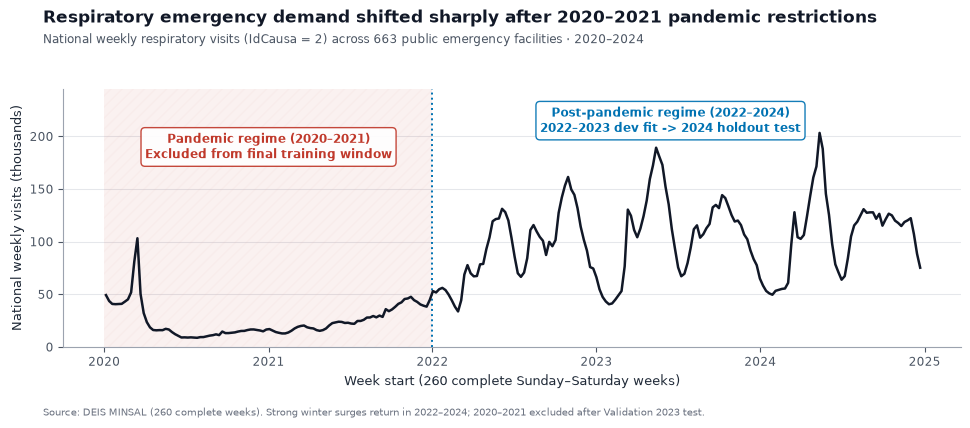

In [4]:
# EDA Figure: 5-year national respiratory trajectory highlighting pandemic regime shift
nat_5y = fw.groupby('week_start')['resp'].sum() / 1000.0

fig, ax = plt.subplots(figsize=(10.2, 4.3))
fig.subplots_adjust(left=0.08, right=0.96, top=0.78, bottom=0.18)
style_axes(ax, grid_axis='y')

ax.axvspan(pd.Timestamp('2020-01-01'), pd.Timestamp('2021-12-31'),
           facecolor=PALETTE['alert'], alpha=0.07, hatch='///', edgecolor='#E6B0AA', lw=0)
ax.axvline(pd.Timestamp('2022-01-01'), color=PALETTE['model'], ls=':', lw=1.4)
ax.plot(nat_5y.index, nat_5y.values, color=PALETTE['observed'], lw=1.8)

ax.text(pd.Timestamp('2021-01-01'), 190, 'Pandemic regime (2020–2021)\nExcluded from final training window',
        ha='center', va='center', fontsize=8.3, fontweight='bold', color=PALETTE['alert'],
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor=PALETTE['alert'], alpha=0.92))
ax.text(pd.Timestamp('2023-06-15'), 215, 'Post-pandemic regime (2022–2024)\n2022–2023 dev fit -> 2024 holdout test',
        ha='center', va='center', fontsize=8.3, fontweight='bold', color=PALETTE['model'],
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor=PALETTE['model'], alpha=0.92))

ax.set_ylim(0, 245)
ax.set_ylabel('National weekly visits (thousands)')
ax.set_xlabel('Week start (260 complete Sunday–Saturday weeks)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

add_header_footer(
    fig,
    title='Respiratory emergency demand shifted sharply after 2020–2021 pandemic restrictions',
    subtitle='National weekly respiratory visits (IdCausa = 2) across 663 public emergency facilities · 2020–2024',
    footer='Source: DEIS MINSAL (260 complete weeks). Strong winter surges return in 2022–2024; 2020–2021 excluded after Validation 2023 test.',
)
plt.show()

## 3. Empirical DEIS Publication-Lag Audit (`Wed 4 Nov 2026` Probe)

In W2, instructor feedback flagged that features dated at week $t$ may not be complete on Monday morning. We audited the live `2026` DEIS archive downloaded on **Wednesday 4 Nov 2026** (last date `2026-11-03`) against the `2025` same-weekday facility count (`n ≈ 626 facilities/day`), re-mapping reporting-day ages (`1–21 days`) to a Monday decision under the assumption that completeness depends primarily on age in days:
* **Age 1 day (yesterday):** `17%` reported — unusable (`[!] Excluded`).
* **Age 2 days (Saturday of week $t$ on Monday):** `82%` reported.
* **Week $t$ on Monday (ages 2–8 days):** `94.3%` average completeness — excluded in strict lag-safe models (`C2`), **nowcasted** via weekday-weighted Chain-Ladder in our updated model (`C3`).
* **Week $t-1$ on Monday (ages 9–15 days):** `99.1%` average completeness — settled lag inputs used by all models.

In [5]:
lag = pd.read_csv(LAG_PATH)
lag_21 = lag.loc[lag['days_before_probe'].between(1, 21)].sort_values('days_before_probe')
lag_summary = pd.DataFrame([
    ('Age 1 day (yesterday)', f"{lag_21.loc[lag_21.days_before_probe.eq(1), 'facility_ratio'].iloc[0]*100:.1f}%", 'Excluded on Monday'),
    ('Age 2 days (Sat of week t)', f"{lag_21.loc[lag_21.days_before_probe.eq(2), 'facility_ratio'].iloc[0]*100:.1f}%", 'Incomplete tail of week t'),
    ('Week t average (ages 2–8)', f"{lag_21.loc[lag_21.days_before_probe.between(2, 8), 'facility_ratio'].mean()*100:.1f}%", 'Excluded in C2; simulated nowcast in C3'),
    ('Week t-1 average (ages 9–15)', f"{lag_21.loc[lag_21.days_before_probe.between(9, 15), 'facility_ratio'].mean()*100:.1f}%", 'Settled lag inputs (all models)'),
], columns=['Reporting-Day Age Window', 'Completeness (% of 2025)', 'Operational Role'])
display(lag_summary)

,Reporting-Day Age Window,Completeness (% of 2025),Operational Role
0,Age 1 day (yesterday),16.7%,Excluded on Monday
1,Age 2 days (Sat of week t),81.6%,Incomplete tail of week t
2,Week t average (ages 2–8),94.3%,Excluded in C2; simulated nowcast in C3
3,Week t-1 average (ages 9–15),99.1%,Settled lag inputs (all models)


## 4. Panel Construction, Missing-Value Policy & Chronological Split

* **Missing-Value Policy (V8):** Facility-weeks with zero reported days remain `NaN` (missing), **never** coerced to zero, so missing reports are not confused with zero demand.
* **Row Inclusion Filter:** Keep rows where the facility had reported at least once by week $t$ (`ever_reported_by_t`) and the target week $t+2$ had all 7 days reported (`target_reporting_days == 7`), yielding **`149,997` modeling rows across `663` facilities**.
* **Strict Chronological Out-of-Time Split (by `target_week_end` year):**
  * **Train:** `2020–2022` (`87,937` rows; post-pandemic `2022-only` subset = `31,696` rows)
  * **Validation:** `2023` (`30,939` rows — used to select training window & model specs)
  * **Test (Holdout):** `2024` (`31,121` rows across `633` facilities — scored after development refit on `2022–2023`, `62,635` rows)

In [6]:
grid = pd.MultiIndex.from_product([sorted(fw.IdEstablecimiento.unique()), sorted(complete_weeks)],
                                  names=['IdEstablecimiento', 'week_start'])
panel = fw.set_index(['IdEstablecimiento', 'week_start']).reindex(grid).reset_index()
panel['reporting_days'] = panel.reporting_days.fillna(0).astype(int)
panel['nonresp'] = panel['all'] - panel.resp
panel['share'] = panel.resp / panel['all'].replace(0, np.nan)

g = panel.groupby('IdEstablecimiento', group_keys=False)
panel['target_resp'] = g.resp.shift(-2)
panel['target_week_start'] = g.week_start.shift(-2)
panel['target_reporting_days'] = g.reporting_days.shift(-2)
panel['ever_reported_by_t'] = g.reporting_days.cumsum().gt(0)
panel['resp_l1'] = g.resp.shift(1)

model_df = (
    panel.loc[panel.ever_reported_by_t & panel.target_reporting_days.eq(7)]
    .rename(columns={'week_start': 'origin_week_start'})
    .reset_index(drop=True)
)
model_df['target_year'] = (model_df.target_week_start + pd.Timedelta(days=6)).dt.year
model_df['split'] = np.select([model_df.target_year.le(2022), model_df.target_year.eq(2023)],
                              ['train', 'validation'], 'test')

split_tbl = (
    model_df.groupby('split', sort=False)
    .agg(
        rows=('target_resp', 'size'),
        facilities=('IdEstablecimiento', 'nunique'),
        target_weeks=('target_week_start', 'nunique'),
        first_target=('target_week_start', lambda s: str(s.min().date())),
        last_target=('target_week_start', lambda s: str(s.max().date())),
        mean_target_visits=('target_resp', 'mean'),
        missing_lag1_rows=('resp_l1', lambda s: int(s.isna().sum())),
    )
    .reindex(['train', 'validation', 'test'])
    .round(1)
)
split_tbl['role'] = [
    'Fit candidates (2022-only subset = 31,696 rows)',
    'Select training window & model specs (2023)',
    'Final out-of-time holdout evaluation (2024)',
]
assert len(model_df) == 149997 and split_tbl.loc['test', 'rows'] == 31121
display(split_tbl)
print('Chronological split verified: 149,997 total rows | 31,121 Test 2024 rows | 54 test rows with missing t-1.')

,rows,facilities,target_weeks,first_target,last_target,mean_target_visits,missing_lag1_rows,role
split,,,,,,,,
train,87937,646,154,2020-01-19,2022-12-25,82.0,750,"Fit candidates (2022-only subset = 31,696 rows)"
validation,30939,631,52,2023-01-01,2023-12-24,176.8,67,Select training window & model specs (2023)
test,31121,633,52,2023-12-31,2024-12-22,175.1,54,Final out-of-time holdout evaluation (2024)


Chronological split verified: 149,997 total rows | 31,121 Test 2024 rows | 54 test rows with missing t-1.
